## **Aprendizaje supervisado**. Predicción de la calidad del vino usando PCA (*Análisis de Componentes Principales*)

In [1]:
import sklearn
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_percentage_error
import matplotlib.pyplot as plt

*   Se cargan los datos del archivo CSV a un **dataframe**. Un dataframe es una estructura de datos con filas y columnas

In [ ]:
dataFrame1=pd.read_csv('data/wines_dataset.csv')
dataFrame1

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,color,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,0,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.99680,3.20,0.68,9.8,0,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.99700,3.26,0.65,9.8,0,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.99800,3.16,0.58,9.8,0,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,0,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...
6492,6.2,0.21,0.29,1.6,0.039,24.0,92.0,0.99114,3.27,0.50,11.2,1,6
6493,6.6,0.32,0.36,8.0,0.047,57.0,168.0,0.99490,3.15,0.46,9.6,1,5
6494,6.5,0.24,0.19,1.2,0.041,30.0,111.0,0.99254,2.99,0.46,9.4,1,6
6495,5.5,0.29,0.30,1.1,0.022,20.0,110.0,0.98869,3.34,0.38,12.8,1,7


*   Se usa el atributo *shape* para conocer cuántas filas y columnas tiene el dataframe

In [3]:
dataFrame1.shape

(6497, 13)

In [4]:
dataFrame1.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,color,quality
count,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000
mean,7.215307,0.339666,0.318633,5.443235,0.056034,30.525319,115.744574,0.994697,3.218501,0.531268,10.491801,0.753886,5.818378
std,1.296434,0.164636,0.145318,4.757804,0.035034,17.749400,56.521855,0.002999,0.160787,0.148806,1.192712,0.430779,0.873255
min,3.800000,0.080000,0.000000,0.600000,0.009000,1.000000,6.000000,0.987110,2.720000,0.220000,8.000000,0.000000,3.000000
25%,6.400000,0.230000,0.250000,1.800000,0.038000,17.000000,77.000000,0.992340,3.110000,0.430000,9.500000,1.000000,5.000000
50%,7.000000,0.290000,0.310000,3.000000,0.047000,29.000000,118.000000,0.994890,3.210000,0.510000,10.300000,1.000000,6.000000
75%,7.700000,0.400000,0.390000,8.100000,0.065000,41.000000,156.000000,0.996990,3.320000,0.600000,11.300000,1.000000,6.000000
max,15.900000,1.580000,1.660000,65.800000,0.611000,289.000000,440.000000,1.038980,4.010000,2.000000,14.900000,1.000000,9.000000


In [5]:
dataFrame1.head(10)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,color,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,0,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,0,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,0,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,0,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,0,5
5,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4,0,5
6,7.9,0.60,0.06,1.6,0.069,15.0,59.0,0.9964,3.30,0.46,9.4,0,5
7,7.3,0.65,0.00,1.2,0.065,15.0,21.0,0.9946,3.39,0.47,10.0,0,7
8,7.8,0.58,0.02,2.0,0.073,9.0,18.0,0.9968,3.36,0.57,9.5,0,7
9,7.5,0.50,0.36,6.1,0.071,17.0,102.0,0.9978,3.35,0.80,10.5,0,5


*   Se usa *info()* para conocer las columnas del dataframe, la cantidad de datos nulos, el tipo de datos de cada columna, y la cantidad de filas

In [6]:
dataFrame1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         6497 non-null   float64
 1   volatile acidity      6497 non-null   float64
 2   citric acid           6497 non-null   float64
 3   residual sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free sulfur dioxide   6497 non-null   float64
 6   total sulfur dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  color                 6497 non-null   int64  
 12  quality               6497 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 660.0 KB


*   Se usa la librería **matplotlib** para graficar la relación entre las columnas *km_drive* y *selling_price* del dataframe





Text(0, 0.5, 'sulphates')

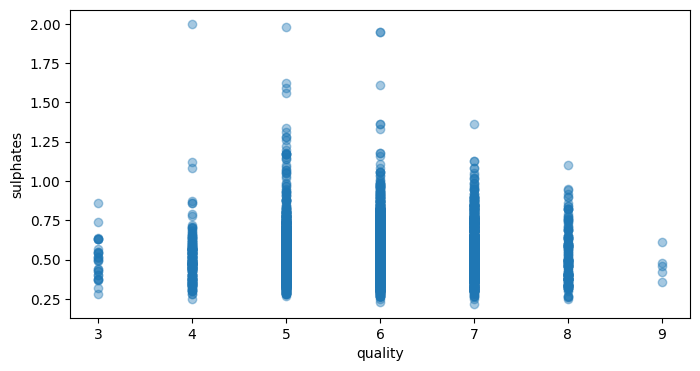

In [7]:
fig, ax = plt.subplots(1, 1, figsize=(8,4))
ax.scatter(x=dataFrame1.quality, y=dataFrame1.sulphates, alpha= 0.4)
ax.set_xlabel('quality')
ax.set_ylabel('sulphates')


*   Se usa la librería **matplotlib** para graficar la relación entre las columnas *year* y *selling_price* del dataframe

Text(0, 0.5, 'residual sugar')

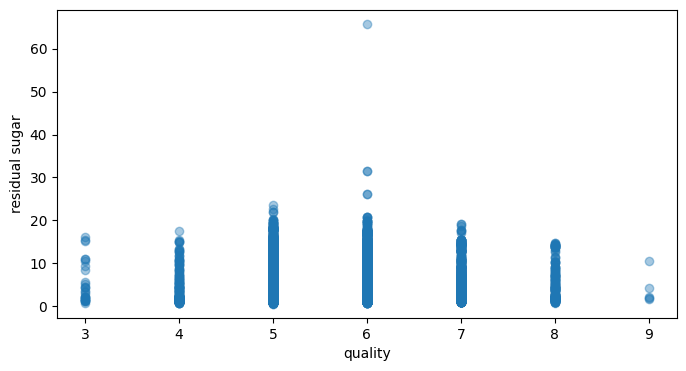

In [8]:
fig, ax = plt.subplots(1, 1, figsize=(8,4))
ax.scatter(x=dataFrame1.quality, y=dataFrame1["residual sugar"], alpha= 0.4)
ax.set_xlabel('quality')
ax.set_ylabel('residual sugar')

*   Se crea un nuevo dataframe con las **variables independientes** que nos interesan

In [9]:
X = dataFrame1[["fixed acidity", "volatile acidity", "citric acid", "residual sugar", "chlorides", "free sulfur dioxide", "total sulfur dioxide", "density", "pH", "sulphates", "alcohol", "color"]]
X

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,color
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.99680,3.20,0.68,9.8,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.99700,3.26,0.65,9.8,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.99800,3.16,0.58,9.8,0
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,0
...,...,...,...,...,...,...,...,...,...,...,...,...
6492,6.2,0.21,0.29,1.6,0.039,24.0,92.0,0.99114,3.27,0.50,11.2,1
6493,6.6,0.32,0.36,8.0,0.047,57.0,168.0,0.99490,3.15,0.46,9.6,1
6494,6.5,0.24,0.19,1.2,0.041,30.0,111.0,0.99254,2.99,0.46,9.4,1
6495,5.5,0.29,0.30,1.1,0.022,20.0,110.0,0.98869,3.34,0.38,12.8,1


*   Se crea un nuevo dataframe con la **variable dependiente**

In [10]:
Y = dataFrame1[["quality"]]
Y

,quality
0,5
1,5
2,5
3,6
4,5
...,...
6492,6
6493,5
6494,6
6495,7


*   Se separa el conjunto de datos en **80% para el entrenamiento** y **20% para pruebas**. La separación se hace indicando el dataframe que tiene las variables independientes (X) y el dataframe con la variable dependiente (Y)

In [11]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size = 0.2)

In [12]:
X_train.shape

(5197, 12)

In [13]:
X_test.shape

(1300, 12)

*   Se entrena un modelo de regresión

In [14]:
modelo1 = LinearRegression()
modelo1.fit(X_train,Y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


*   Una vez entrenado el modelo, se usa para hacer las predicciones sobre el conjunto de prueba. Al modelo solo se le pasan los valores de X, es decir, los variables independiente en el conjunto de prueba

In [15]:
predicciones = modelo1.predict(X_test)
predicciones

array([[6.19276805],
       [6.21557323],
       [5.17859841],
       ...,
       [5.7202165 ],
       [5.89236669],
       [6.17774923]], shape=(1300, 1))

*   Se calculan las medidas de error para conocer si el modelo logra predecir los valores de las vehículos en el conjunto de prueba

In [16]:
MAE = metrics.mean_absolute_error(Y_test, predicciones)
RMSE=np.sqrt(mean_squared_error(Y_test, predicciones))
coeficiente=r2_score(Y_test, predicciones)
MAPE=mean_absolute_percentage_error(Y_test, predicciones)

print("MAE = ",MAE)
print("RMSE = ",RMSE)
print("Coeficiente de determinación = ",coeficiente)
print("MAPE (Mean absolute percentage error) = ",MAPE)

MAE =  0.5599034909514105
RMSE =  0.7292227805458262
Coeficiente de determinación =  0.27199677460084926
MAPE (Mean absolute percentage error) =  0.10040749374232315


In [17]:
resultados=Y_test
resultados["predicciones"]=predicciones
resultados["Diferencia"]=abs(Y_test["predicciones"]-Y_test["quality"])
resultados

,quality,predicciones,Diferencia
4272,6,6.192768,0.192768
6342,5,6.215573,1.215573
2395,6,5.178598,0.821402
5338,7,5.631080,1.368920
5935,8,5.554495,2.445505
...,...,...,...
6468,6,5.724978,0.275022
3575,5,5.604309,0.604309
1027,5,5.720216,0.720216
5011,6,5.892367,0.107633


# **PCA.** *Principal Component Analysis* (PCA)
Es un método estadístico que permite simplificar la complejidad de espacios muestrales que tienen muchas dimensiones a la vez que conserva su información. Supóngase que existe una muestra con n individuos cada uno con p variables (X<sub>1</sub>, X<sub>2</sub>, …, X<sub>p</sub>), es decir, el espacio muestral tiene p dimensiones. PCA permite encontrar un número de factores subyacentes (z<p) que explican aproximadamente lo mismo que las p variables originales. Donde antes se necesitaban p valores para caracterizar a cada individuo, ahora bastan z valores. Cada una de estas z nuevas variables recibe el nombre de **componente principal**.

In [18]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2)
componentes=pca.fit_transform(X)



*   Porcentaje de la varianza explicada para cada componente



In [19]:
print(pca.explained_variance_ratio_)

[0.95373371 0.04062598]


In [20]:
pca_dataFrame = pd.DataFrame(data=componentes, columns=['Componente 1','Componente 2'])
pca_dataFrame

,Componente 1,Componente 2
0,-84.113923,-0.144230
1,-48.782678,5.848745
2,-63.737621,-0.875201
3,-57.484397,-0.343775
4,-84.113923,-0.144230
...,...,...
6492,-24.739907,-0.917331
6493,57.017862,13.706874
6494,-4.894804,0.507762
6495,-8.187142,-8.974109


In [21]:
X_train2, X_test2, Y_train2, Y_test2 = train_test_split(pca_dataFrame, Y, test_size = 0.2)

In [22]:
modelo2 = LinearRegression()
modelo2.fit(X_train2,Y_train2)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [23]:
predicciones2 = modelo2.predict(X_test2)
predicciones2

array([[5.83527655],
       [5.86870993],
       [5.91997246],
       ...,
       [5.72907306],
       [5.61845051],
       [5.65507661]], shape=(1300, 1))

In [24]:
MAE = metrics.mean_absolute_error(Y_test2, predicciones2)
RMSE=np.sqrt(mean_squared_error(Y_test2, predicciones2))
coeficiente=r2_score(Y_test2, predicciones2)
MAPE=mean_absolute_percentage_error(Y_test2, predicciones2)

print("MAE = ",MAE)
print("RMSE = ",RMSE)
print("Coeficiente de determinación = ",coeficiente)
print("MAPE (Mean absolute percentage error) = ",MAPE)

MAE =  0.6839007401124955
RMSE =  0.8840017226804529
Coeficiente de determinación =  0.005231361267424073
MAPE (Mean absolute percentage error) =  0.1222344454050558


In [25]:
resultados=Y_test2
resultados["predicciones"]=predicciones2
resultados["Diferencia"]=abs(Y_test2["predicciones"]-Y_test2["quality"])
resultados

,quality,predicciones,Diferencia
3904,7,5.835277,1.164723
748,6,5.868710,0.131290
1786,5,5.919972,0.919972
3018,7,5.817684,1.182316
3503,6,5.967752,0.032248
...,...,...,...
3004,4,5.606023,1.606023
715,6,5.870310,0.129690
4218,6,5.729073,0.270927
2156,6,5.618451,0.381549
